# Praktikum Data Mining: Klasifikasi Ensemble & Penanganan Class Imbalance
**Muhammad Fardan Hafidz - 5054251021**

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

### 1. Unduh dan Import Dataset

In [2]:
# membaca dataset transaksi kartu kredit
df = pd.read_csv('creditcard.csv')

display(df.head())
print("Dimensi dataset:", df.shape)
df.info()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Dimensi dataset: (284807, 31)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non

In [3]:
# cek ketiadaan nilai hilang (missing values)
print("Jumlah missing values per kolom:")
print(f"Total missing: {df.isnull().sum().sum()}")
display(df.isnull().sum().head())

Jumlah missing values per kolom:
Total missing: 0


Time    0
V1      0
V2      0
V3      0
V4      0
dtype: int64

### 2. Praproses Data & Analisis Distribusi Kelas

In [4]:
# identifikasi distribusi kelas target (Class)
class_counts = df['Class'].value_counts()
class_pct = df['Class'].value_counts(normalize=True) * 100

dist_df = pd.DataFrame({
    'Jumlah Transaksi': class_counts,
    'Persentase (%)': class_pct
})
dist_df.index = ['Normal (0)', 'Fraud (1)']
display(dist_df)

,Jumlah Transaksi,Persentase (%)
Normal (0),284315,99.827251
Fraud (1),492,0.172749


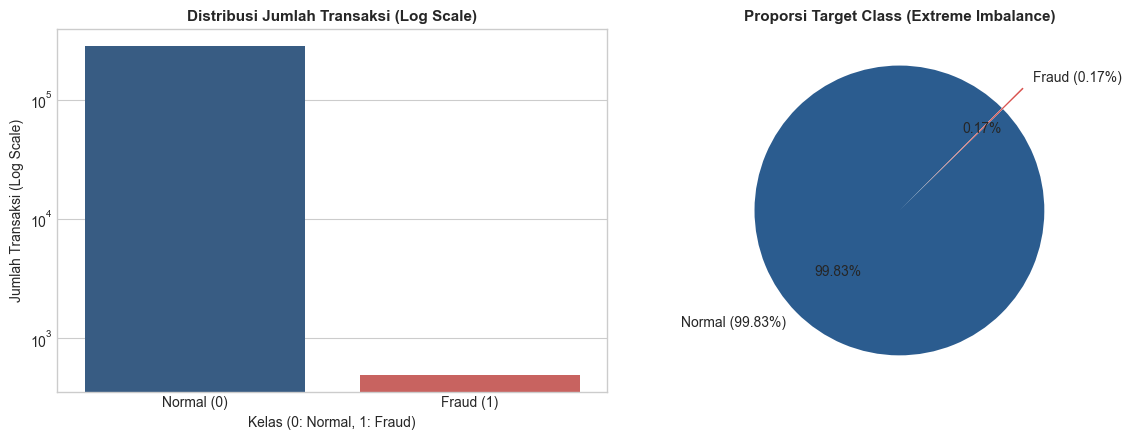

In [5]:
# visualisasi distribusi kelas target (skala logaritmik dan diagram donut)
plt.figure(figsize=(12, 4.5))

plt.subplot(1, 2, 1)
sns.barplot(x=class_counts.index, y=class_counts.values, hue=class_counts.index, palette=['#2b5c8f', '#d9534f'], legend=False)
plt.yscale('log')
plt.title('Distribusi Jumlah Transaksi (Log Scale)', fontsize=11, fontweight='bold')
plt.xlabel('Kelas (0: Normal, 1: Fraud)')
plt.ylabel('Jumlah Transaksi (Log Scale)')
plt.xticks([0, 1], ['Normal (0)', 'Fraud (1)'])

plt.subplot(1, 2, 2)
plt.pie(class_counts, labels=['Normal (99.83%)', 'Fraud (0.17%)'], 
        colors=['#2b5c8f', '#d9534f'], autopct='%1.2f%%', startangle=45,
        explode=(0, 0.2))
plt.title('Proporsi Target Class (Extreme Imbalance)', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

In [6]:
# penyetaraan skala fitur numerik Time dan Amount dengan RobustScaler
# fitur V1 hingga V28 merupakan komponen PCA terstandarisasi sehingga tidak perlu di-scaling ulang
scaler = RobustScaler()
df[['Time', 'Amount']] = scaler.fit_transform(df[['Time', 'Amount']])

display(df[['Time', 'Amount']].describe())

,Time,Amount
count,284807.000000,284807.000000
mean,0.118914,0.927124
std,0.557903,3.495006
min,-0.994983,-0.307413
25%,-0.358210,-0.229162
50%,0.000000,0.000000
75%,0.641790,0.770838
max,1.035022,358.683155


In [7]:
# pemisahan fitur dan target serta pembagian data latih dan uji (80:20) secara terstratifikasi
X = df.drop(columns=['Class'])
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Jumlah sampel latih: {X_train.shape[0]:,} (Fraud: {y_train.sum()} | {y_train.mean():.4%})")
print(f"Jumlah sampel uji  : {X_test.shape[0]:,} (Fraud: {y_test.sum()} | {y_test.mean():.4%})")

Jumlah sampel latih: 227,845 (Fraud: 394 | 0.1729%)
Jumlah sampel uji  : 56,962 (Fraud: 98 | 0.1720%)


### 3. Penanganan Class Imbalance pada Data Latih
Resampling **hanya dilakukan pada data latih** (`X_train`, `y_train`). Data uji (`X_test`, `y_test`) tetap dibiarkan sesuai distribusi aslinya untuk mencegah kebocoran data (*data leakage*).

In [8]:
# 1. Penerapan SMOTE (Oversampling)
smote = SMOTE(sampling_strategy=0.2, random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# 2. Penerapan Random UnderSampler (Undersampling)
rus = RandomUnderSampler(sampling_strategy=0.5, random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)

resampling_df = pd.DataFrame({
    'Strategi': ['Asli (Train)', 'SMOTE (Oversampling)', 'RUS (Undersampling)'],
    'Total Data': [len(y_train), len(y_train_smote), len(y_train_rus)],
    'Normal (0)': [(y_train == 0).sum(), (y_train_smote == 0).sum(), (y_train_rus == 0).sum()],
    'Fraud (1)': [(y_train == 1).sum(), (y_train_smote == 1).sum(), (y_train_rus == 1).sum()],
    'Persentase Fraud (%)': [y_train.mean()*100, y_train_smote.mean()*100, y_train_rus.mean()*100]
})
display(resampling_df)

,Strategi,Total Data,Normal (0),Fraud (1),Persentase Fraud (%)
0,Asli (Train),227845,227451,394,0.172925
1,SMOTE (Oversampling),272941,227451,45490,16.666606
2,RUS (Undersampling),1182,788,394,33.333333


### 4. Membangun Model Klasifikasi Ensemble & Benchmarking

In [9]:
# fungsi helper untuk melatih dan mengevaluasi performa model
def train_and_eval(name, model, x_tr, y_tr, x_te, y_te):
    t0 = time.time()
    model.fit(x_tr, y_tr)
    dur = time.time() - t0
    
    y_pred = model.predict(x_te)
    y_prob = model.predict_proba(x_te)[:, 1]
    
    metrics = {
        'Model': name,
        'Accuracy': accuracy_score(y_te, y_pred),
        'Precision (Fraud)': precision_score(y_te, y_pred, zero_division=0),
        'Recall (Fraud)': recall_score(y_te, y_pred),
        'F1-Score (Fraud)': f1_score(y_te, y_pred),
        'ROC-AUC': roc_auc_score(y_te, y_prob),
        'PR-AUC': average_precision_score(y_te, y_prob),
        'Training Time (s)': dur
    }
    return metrics, y_pred, y_prob, model

In [10]:
# mendefinisikan dan melatih seluruh model benchmark
model_configs = [
    ("RF (Baseline)", RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1), X_train, y_train),
    ("XGB (Baseline)", XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1, eval_metric='logloss'), X_train, y_train),
    ("RF + SMOTE", RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1), X_train_smote, y_train_smote),
    ("XGB + SMOTE", XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1, eval_metric='logloss'), X_train_smote, y_train_smote),
    ("RF + RUS", RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1), X_train_rus, y_train_rus),
    ("XGB + RUS", XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1, eval_metric='logloss'), X_train_rus, y_train_rus),
    ("RF (Cost-Sensitive)", RandomForestClassifier(n_estimators=100, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1), X_train, y_train),
]

results_list = []
predictions = {}
probabilities = {}
models_dict = {}

for name, clf, x_tr, y_tr in model_configs:
    res, y_pred, y_prob, trained_clf = train_and_eval(name, clf, x_tr, y_tr, X_test, y_test)
    results_list.append(res)
    predictions[name] = y_pred
    probabilities[name] = y_prob
    models_dict[name] = trained_clf
    print(f"[*] {name:<20} | Recall: {res['Recall (Fraud)']:.4f} | Prec: {res['Precision (Fraud)']:.4f} | F1: {res['F1-Score (Fraud)']:.4f} | PR-AUC: {res['PR-AUC']:.4f}")

[*] RF (Baseline)        | Recall: 0.8061 | Prec: 0.9294 | F1: 0.8634 | PR-AUC: 0.8644


[*] XGB (Baseline)       | Recall: 0.7959 | Prec: 0.8966 | F1: 0.8432 | PR-AUC: 0.8342


[*] RF + SMOTE           | Recall: 0.8673 | Prec: 0.7727 | F1: 0.8173 | PR-AUC: 0.8703


[*] XGB + SMOTE          | Recall: 0.8469 | Prec: 0.5804 | F1: 0.6888 | PR-AUC: 0.8516


[*] RF + RUS             | Recall: 0.8980 | Prec: 0.0807 | F1: 0.1480 | PR-AUC: 0.7101


[*] XGB + RUS            | Recall: 0.9082 | Prec: 0.0500 | F1: 0.0947 | PR-AUC: 0.6882


[*] RF (Cost-Sensitive)  | Recall: 0.8061 | Prec: 0.8316 | F1: 0.8187 | PR-AUC: 0.8320


In [11]:
# membangun Soft Voting Ensemble dengan memadukan probabilitas model-model terbaik
y_prob_vote = (probabilities['RF + SMOTE'] + probabilities['XGB + SMOTE'] + probabilities['RF (Cost-Sensitive)']) / 3.0
y_pred_vote = (y_prob_vote >= 0.5).astype(int)

vote_res = {
    'Model': 'Ensemble (Soft Voting)',
    'Accuracy': accuracy_score(y_test, y_pred_vote),
    'Precision (Fraud)': precision_score(y_test, y_pred_vote, zero_division=0),
    'Recall (Fraud)': recall_score(y_test, y_pred_vote),
    'F1-Score (Fraud)': f1_score(y_test, y_pred_vote),
    'ROC-AUC': roc_auc_score(y_test, y_prob_vote),
    'PR-AUC': average_precision_score(y_test, y_prob_vote),
    'Training Time (s)': 0.0
}
results_list.append(vote_res)
predictions['Ensemble (Soft Voting)'] = y_pred_vote
probabilities['Ensemble (Soft Voting)'] = y_prob_vote

print(f"[+] Ensemble (Soft Voting) | Recall: {vote_res['Recall (Fraud)']:.4f} | Prec: {vote_res['Precision (Fraud)']:.4f} | ROC-AUC: {vote_res['ROC-AUC']:.4f} | PR-AUC: {vote_res['PR-AUC']:.4f}")

[+] Ensemble (Soft Voting) | Recall: 0.8469 | Prec: 0.7685 | ROC-AUC: 0.9832 | PR-AUC: 0.8594


### 5. Evaluasi dan Perbandingan Performa Model

In [12]:
# ringkasan tabel hasil benchmark metrik evaluasi
df_results = pd.DataFrame(results_list)
display(df_results.sort_values(by='PR-AUC', ascending=False).reset_index(drop=True))

,Model,Accuracy,Precision (Fraud),Recall (Fraud),F1-Score (Fraud),ROC-AUC,PR-AUC,Training Time (s)
0,RF + SMOTE,0.999333,0.772727,0.867347,0.817308,0.981646,0.870284,28.164337
1,RF (Baseline),0.999561,0.929412,0.806122,0.863388,0.976869,0.864393,26.119208
2,Ensemble (Soft Voting),0.999298,0.768519,0.846939,0.805825,0.983221,0.859403,0.000000
3,XGB + SMOTE,0.998683,0.580420,0.846939,0.688797,0.977429,0.851587,1.749490
4,XGB (Baseline),0.999491,0.896552,0.795918,0.843243,0.960115,0.834176,1.396500
5,RF (Cost-Sensitive),0.999386,0.831579,0.806122,0.818653,0.975322,0.832013,18.480233
6,RF + RUS,0.982216,0.080660,0.897959,0.148024,0.977011,0.710061,0.188674
7,XGB + RUS,0.970138,0.049972,0.908163,0.094731,0.971478,0.688225,0.158196


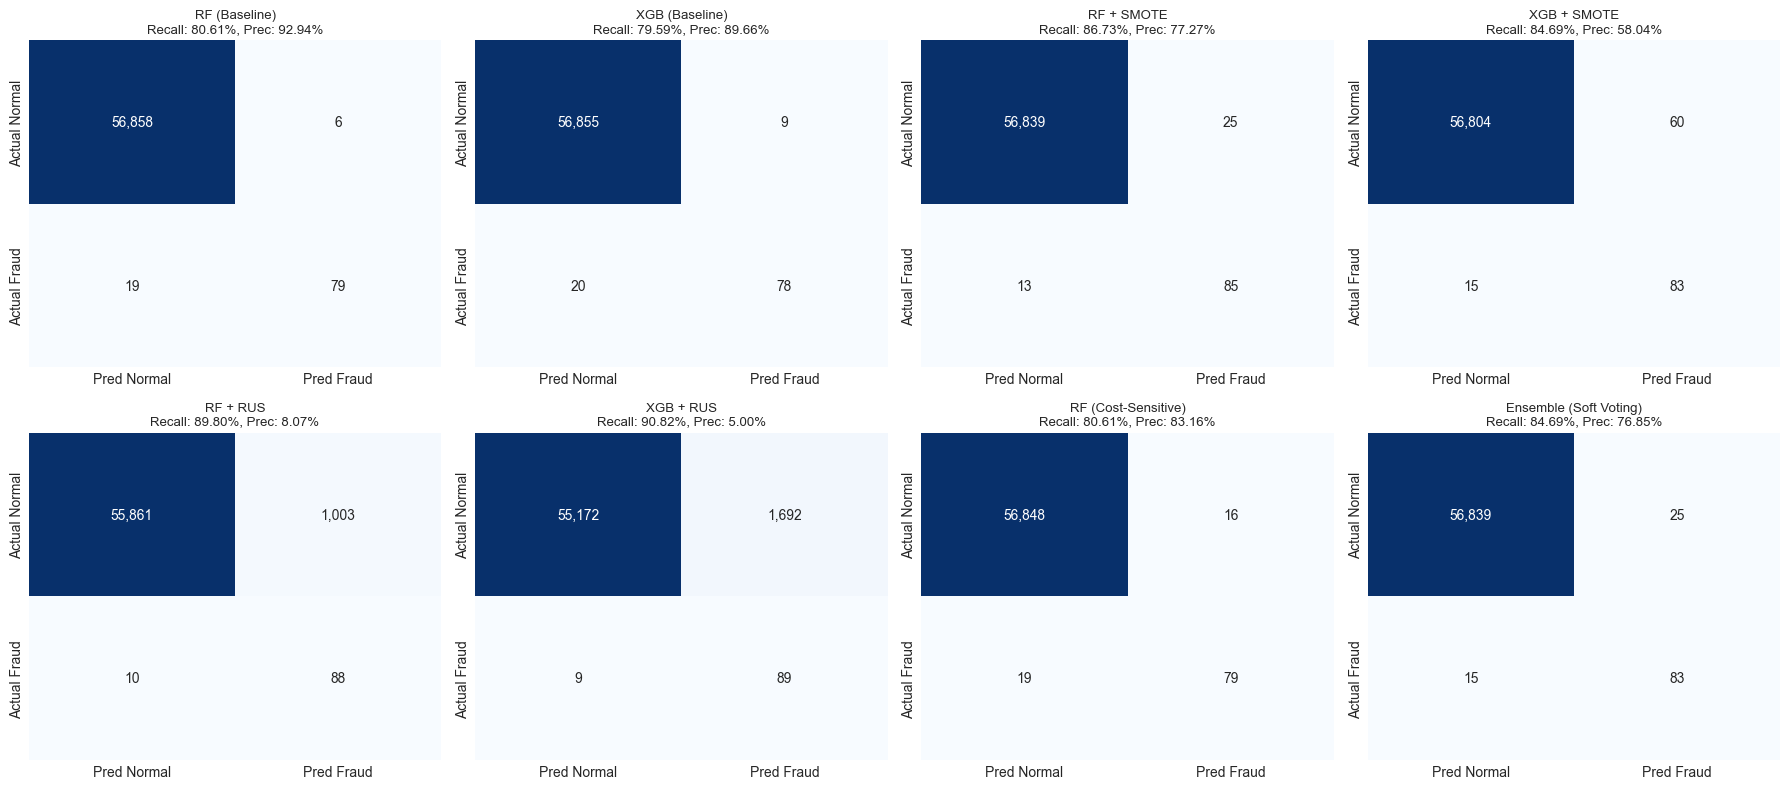

In [13]:
# visualisasi confusion matrix untuk seluruh model
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, (m_name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=axes[i],
                xticklabels=['Pred Normal', 'Pred Fraud'],
                yticklabels=['Actual Normal', 'Actual Fraud'])
    axes[i].set_title(f"{m_name}\nRecall: {recall_score(y_test, y_pred):.2%}, Prec: {precision_score(y_test, y_pred, zero_division=0):.2%}", fontsize=9.5)

plt.tight_layout()
plt.show()

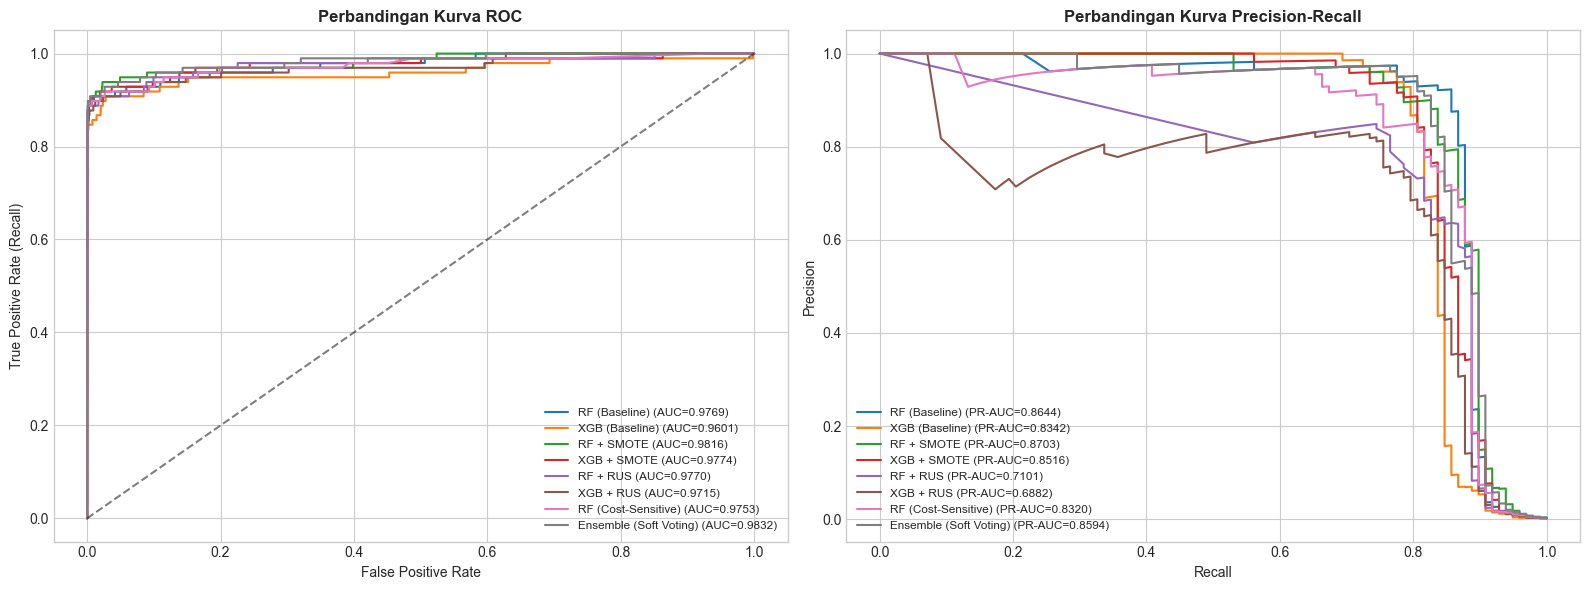

In [14]:
# visualisasi kurva ROC dan kurva Precision-Recall
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

for m_name, y_prob in probabilities.items():
    # ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    ax[0].plot(fpr, tpr, label=f"{m_name} (AUC={auc:.4f})")
    
    # PR Curve
    prec, rec, _ = precision_recall_curve(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)
    ax[1].plot(rec, prec, label=f"{m_name} (PR-AUC={pr_auc:.4f})")

ax[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax[0].set_title('Perbandingan Kurva ROC', fontsize=12, fontweight='bold')
ax[0].set_xlabel('False Positive Rate')
ax[0].set_ylabel('True Positive Rate (Recall)')
ax[0].legend(loc='lower right', fontsize=8.5)

ax[1].set_title('Perbandingan Kurva Precision-Recall', fontsize=12, fontweight='bold')
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')
ax[1].legend(loc='lower left', fontsize=8.5)

plt.tight_layout()
plt.show()

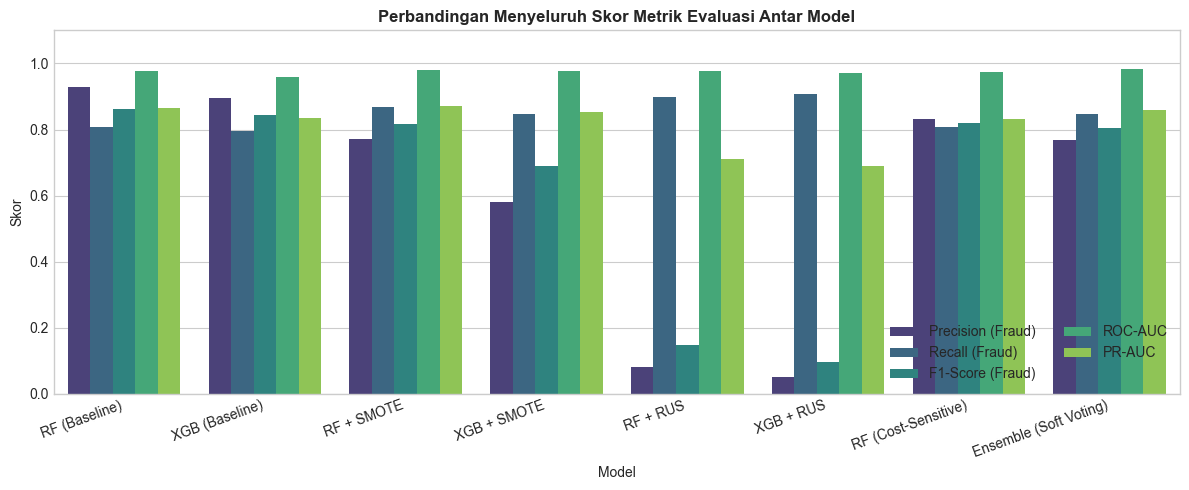

In [15]:
# perbandingan skor metrik evaluasi antar model
plot_data = df_results.melt(id_vars=['Model'], 
                           value_vars=['Precision (Fraud)', 'Recall (Fraud)', 'F1-Score (Fraud)', 'ROC-AUC', 'PR-AUC'],
                           var_name='Metrik', value_name='Skor')

plt.figure(figsize=(12, 5))
sns.barplot(data=plot_data, x='Model', y='Skor', hue='Metrik', palette='viridis')
plt.title('Perbandingan Menyeluruh Skor Metrik Evaluasi Antar Model', fontsize=12, fontweight='bold')
plt.xticks(rotation=20, ha='right')
plt.ylim([0, 1.1])
plt.legend(loc='lower right', ncol=2)
plt.tight_layout()
plt.show()

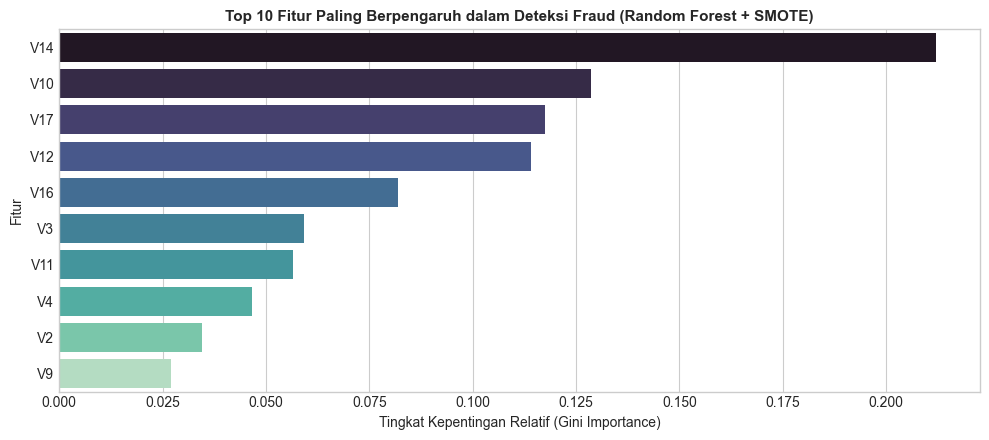

In [16]:
# ekstraksi tingkat kepentingan fitur (feature importance) dari Random Forest + SMOTE
rf_model = models_dict['RF + SMOTE']
fi = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 4.5))
sns.barplot(x=fi.values, y=fi.index, hue=fi.index, palette='mako', legend=False)
plt.title('Top 10 Fitur Paling Berpengaruh dalam Deteksi Fraud (Random Forest + SMOTE)', fontsize=11, fontweight='bold')
plt.xlabel('Tingkat Kepentingan Relatif (Gini Importance)')
plt.ylabel('Fitur')
plt.tight_layout()
plt.show()

### 6. Analisis Hasil & Pembahasan

#### Mengapa Accuracy Saja Tidak Cukup untuk Dataset Ini?
Pada dataset transaksi kartu kredit dengan ketidakseimbangan kelas ekstrem (99,83% transaksi normal dan hanya 0,17% transaksi penipuan):
1. **Paradoks Akurasi**: Jika model secara naif menebak semua transaksi adalah "Normal" (`Class = 0`), model tersebut secara matematis akan memperoleh **akurasi sebesar 99,827%**.
2. **Ketiadaan Nilai Guna**: Meskipun akurasinya tampak sangat tinggi, model tersebut memiliki nilai kegunaan **nol** di industri perbankan karena gagal menangkap 100% kasus penipuan (*Recall = 0%*).
3. **Asimetri Biaya Bisnis**: Kerugian akibat membiarkan penipuan lolos (*False Negative*) jauh lebih besar dibandingkan beban operasional melakukan verifikasi transaksi legal yang dicurigai (*False Positive*).
4. Oleh karena itu, metrik yang wajib digunakan adalah **Recall** (daya tangkap fraud), **Precision** (akurasi alarm fraud), **F1-Score**, serta **Precision-Recall AUC (PR-AUC)**.

#### Kesimpulan Hasil Eksperimen:
- **Baseline Model**: Memiliki presisi tinggi (>89%), namun Recall relatif rendah (~80%), meloloskan ~20 kasus fraud pada data uji.
- **SMOTE (Oversampling)**: Meningkatkan Recall secara signifikan menjadi **86,73%** (RF) dan **84,69%** (XGB), dengan nilai PR-AUC tertinggi (**0,8703**), menjaga jumlah alarm palsu tetap rendah.
- **Random UnderSampler (RUS)**: Menghasilkan Recall tertinggi (~90,8%), tetapi presisi anjlok ke level **5%** akibat membuang mayoritas data normal, memicu ribuan alarm palsu.
- **Soft Voting Ensemble**: Menggabungkan probabilitas model terbaik menghasilkan model dengan **ROC-AUC tertinggi (0,9832)** dan probabilitas yang paling stabil.